### Unsupervised Deep Learning
#### Assignment 2
#### Image Generation using (β-)VAE, VQ-VAE with PixelCNN prior and WGAN / WGAN-GP
##### Part A: (β-)VAE and VQ-VAE with a PixelCNN prior

##### Group 6

Students' details

|Name|BITS ID| Contribution %|
|---|---|---|
|Brincita Prima Cutinha | 2025AG05256 | 100 |
|Devang Ajay Kamble | 2025AE05173 | 100 |
|Saksham Jindal | 2025AE05983 | 100 |
|Shantanu Biswas | 2025AE05079 | 100 |
|Ashish Chauhan | 2025AG05928 | 100 |

#### Prerequisites

This notebook was developed and tested with the following environment.

**Python:** 3.10+

**Packages:**

| Package | Used for |
|---|---|
| `torch` / `torchvision` (CUDA build) | models, training, CIFAR-10 loader |
| `numpy` | array/numeric operations |
| `pandas` | results tables |
| `matplotlib` | plotting (curves, reconstructions, sample grids) |
| `scipy` | matrix square root inside the FID computation |
| `pytorch-fid` | pretrained Inception-v3 (pool3, 2048-d) used for FID, precision and recall |
| `pillow` | saving image grids |

Run the cell below once to install

In [1]:
# Uncomment the line below to install any missing packages in this environment.
# %pip install -q torch torchvision numpy pandas matplotlib scipy pytorch-fid pillow

import sys
import numpy
import pandas
import matplotlib
import scipy
import PIL
import torch
import torchvision
import pytorch_fid

print("Python      :", sys.version.split()[0])
print("numpy       :", numpy.__version__)
print("pandas      :", pandas.__version__)
print("matplotlib  :", matplotlib.__version__)
print("scipy       :", scipy.__version__)
print("pillow      :", PIL.__version__)
print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("pytorch-fid :", pytorch_fid.__version__)
print("CUDA        :", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Python      : 3.10.11
numpy       : 2.2.6
pandas      : 2.3.3
matplotlib  : 3.10.9
scipy       : 1.15.3
pillow      : 12.3.0
torch       : 2.5.1+cu121
torchvision : 0.20.1+cu121
pytorch-fid : 0.3.0
CUDA        : True NVIDIA GeForce RTX 3080 Laptop GPU


### Part A-1: (β-)Variational Autoencoder

#### Objective

Train a convolutional VAE on CIFAR-10 for `β ∈ {1, 2, 4, 10}` using the β-VAE objective

`L(β) = E_q(z|x)[ -log p(x|z) ] + β · KL( q(z|x) || N(0, I) )`

and compare (i) reconstruction quality as **PSNR versus epoch**, and (ii) sample realism as **FID** for the
different values of β. As extras we also report precision/recall, the KL term, the number of *active* latent
units, latent interpolations and latent traversals, so that the effect of β can be explained and not only measured.

Expected Result

We expect to see:

* A trade-off controlled by β. A larger β puts more weight on the KL term, pushes the posterior closer to the prior
  and gives a **lower reconstruction PSNR** (blurrier reconstructions); `β = 1` should reconstruct best.
* The KL term (information stored in the code) should **fall monotonically as β grows**, and the number of
  active latent units should shrink, because the model prunes dimensions it cannot afford to encode.
* Samples drawn from `N(0, I)` are expected to be **blurry** for every β — the well-known VAE behaviour of a pixel-wise
  likelihood on natural images — and the FID should therefore be high (roughly in the 100-200 range). A larger β
  makes the aggregate posterior match the prior better, so FID may improve slightly for moderate β even though
  reconstruction gets worse.

#### Imports

In [2]:
# imports
import os
import json
import time
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from scipy import linalg

#### Configuration

In [3]:
# Global configuration
# Set UDL_SMOKE=1 in the environment for a 1-minute dry run of the whole notebook.
SMOKE = os.environ.get("UDL_SMOKE", "0") == "1"

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

RES_DIR = "results_smoke" if SMOKE else "results"
os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(f"{RES_DIR}/samples", exist_ok=True)
os.makedirs(f"{RES_DIR}/figures", exist_ok=True)

N_TRAIN = 5000 if SMOKE else 50000      # number of training images used
N_FID = 1000 if SMOKE else 10000        # generated images per FID evaluation
FID_REPEATS = 1 if SMOKE else 3         # independent sampling rounds -> mean +- std

CFG = dict(
    betas=[1, 2, 4, 10],
    latent_dim=128,
    vae_epochs=1 if SMOKE else 40,
    vae_lr=1e-3,
    batch_size=128,
    ks=[512, 256, 128],
    vq_dim=64,
    vq_epochs=1 if SMOKE else 40,
    vq_lr=5e-4,
    pix_epochs=1 if SMOKE else 40,
    pix_lr=1e-3,
)
RESULTS_PATH = f"{RES_DIR}/partA_results.json"
if os.path.exists(RESULTS_PATH):
    os.remove(RESULTS_PATH)          # a fresh run always rebuilds the results file

def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.benchmark = True

print("Device :", DEVICE, "| smoke run:", SMOKE)
print("Config :", CFG)

Device : cuda | smoke run: False
Config : {'betas': [1, 2, 4, 10], 'latent_dim': 128, 'vae_epochs': 40, 'vae_lr': 0.001, 'batch_size': 128, 'ks': [512, 256, 128], 'vq_dim': 64, 'vq_epochs': 40, 'vq_lr': 0.0005, 'pix_epochs': 40, 'pix_lr': 0.001}


#### Load the dataset & Normalize the data

CIFAR-10 (60,000 colour images, 32x32x3). Pixel values are normalised to `[0, 1]` as required.
The official split is kept (50,000 train / 10,000 test); the whole dataset is held on the GPU as a
tensor, which removes the data-loader overhead from every training loop.

In [4]:
# Load CIFAR-10 and normalise to [0, 1]
def load_cifar10(root="./data"):
    train = torchvision.datasets.CIFAR10(root=root, train=True, download=True)
    test = torchvision.datasets.CIFAR10(root=root, train=False, download=True)

    def to_tensor(arr):
        x = torch.from_numpy(arr).float() / 255.0          # normalise pixels to [0, 1]
        return x.permute(0, 3, 1, 2).contiguous()          # NHWC -> NCHW

    return to_tensor(train.data), to_tensor(test.data)

X_train, X_test = load_cifar10()
X_train = X_train[:N_TRAIN].to(DEVICE)
X_test = X_test.to(DEVICE)

print("train :", tuple(X_train.shape), "range [%.1f, %.1f]" % (X_train.min().item(), X_train.max().item()))
print("test  :", tuple(X_test.shape))
DATA_VAR = X_train.var().item()
print("pixel variance of the training set: %.4f" % DATA_VAR)

Files already downloaded and verified


Files already downloaded and verified


train : (50000, 3, 32, 32) range [0.0, 1.0]
test  : (10000, 3, 32, 32)
pixel variance of the training set: 0.0633


#### Helper Functions

Shared utilities: batching, PSNR, parameter counts and image-grid plotting/saving.

In [5]:
def batches(X, batch_size, shuffle=True):
    # yields mini-batches of a GPU tensor
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X) - (batch_size - 1 if shuffle else 0), batch_size):
        yield X[idx[i:i + batch_size]]


def psnr_per_image(x, x_hat):
    # PSNR (dB) of every image for data in [0, 1]:  10 log10( 1 / MSE )
    mse = ((x - x_hat) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return 10 * torch.log10(1.0 / mse)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def to_grid(imgs, nrow=10, scale=1):
    # imgs: N x 3 x H x W tensor in [0, 1]  ->  H' x W' x 3 numpy array
    g = torchvision.utils.make_grid(imgs.detach().cpu().clamp(0, 1), nrow=nrow, padding=1, pad_value=1.0)
    g = g.permute(1, 2, 0).numpy()
    if scale > 1:
        g = np.kron(g, np.ones((scale, scale, 1)))
    return g


def show_grid(imgs, title="", nrow=10, scale=1, figsize=(7, 7), save=None):
    g = to_grid(imgs, nrow, scale)
    plt.figure(figsize=figsize)
    plt.imshow(g)
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    if save:
        plt.savefig(f"{RES_DIR}/figures/{save}.png", dpi=150, bbox_inches="tight")
    plt.show()


def save_100(imgs, name):
    # keep the 100 images used for the Part-C visual comparison (uint8 -> small files)
    arr = (imgs[:100].detach().cpu().clamp(0, 1).numpy() * 255).round().astype(np.uint8)
    np.save(f"{RES_DIR}/samples/{name}_100.npy", arr)


def update_results(path, key, value):
    # merge one entry into a results JSON file
    data = json.load(open(path)) if os.path.exists(path) else {}
    data[key] = value
    json.dump(data, open(path, "w"), indent=1)

#### Evaluation metrics: FID, Precision and Recall

**FID** (Frechet Inception Distance) compares the Gaussian statistics `(mu, Sigma)` of Inception-v3 pool3
features of real and generated images: `FID = ||mu_r - mu_g||^2 + Tr(S_r + S_g - 2 (S_r S_g)^(1/2))`.
Lower is better.

* **Reference statistics:** the CIFAR-10 *training* set.
* **Generated set:** `N_FID` = 10,000 images; every FID in this notebook is the mean +- std of
  `FID_REPEATS` independent sampling rounds, so a table entry also shows how noisy the metric is.
* **Inception weights:** the standard TF-FID port shipped with `pytorch-fid`, so the numbers are
  comparable with published CIFAR-10 FIDs.

As an extra we also report the k-NN **Precision / Recall** of Kynkaanniemi et al. (2019) on the same
features: precision = fraction of generated images that fall inside the real manifold (*fidelity*),
recall = fraction of real images covered by the generated manifold (*diversity*). FID alone cannot tell
"blurry but diverse" apart from "sharp but mode-collapsed"; these two numbers can.

In [6]:
from pytorch_fid.inception import InceptionV3
from pytorch_fid.fid_score import calculate_frechet_distance

inception = InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]]).to(DEVICE).eval()


@torch.no_grad()
def inception_features(x, batch_size=250):
    # x: N x 3 x H x W in [0, 1]  ->  N x 2048 float64 numpy features
    out = []
    for i in range(0, len(x), batch_size):
        f = inception(x[i:i + batch_size].to(DEVICE).float())[0]
        out.append(f.squeeze(-1).squeeze(-1).double().cpu())
    return torch.cat(out).numpy()


def gaussian_stats(feats):
    return feats.mean(0), np.cov(feats, rowvar=False)


def fid_from_feats(feats, ref_stats):
    mu, sigma = gaussian_stats(feats)
    return float(calculate_frechet_distance(mu, sigma, ref_stats[0], ref_stats[1]))


# ---- reference statistics (cached on disk) --------------------------------------------------
_ref_path = f"{RES_DIR}/cifar10_inception_ref.npz"
if os.path.exists(_ref_path):
    _z = np.load(_ref_path)
    REF_STATS, REAL_FEATS = (_z["mu"], _z["sigma"]), _z["real_feats"]
else:
    _train_feats = inception_features(X_train)
    REF_STATS = gaussian_stats(_train_feats)
    REAL_FEATS = inception_features(X_test)[:N_FID]            # real manifold for precision/recall
    np.savez(_ref_path, mu=REF_STATS[0], sigma=REF_STATS[1], real_feats=REAL_FEATS)

print("reference stats ready | real features for P/R:", REAL_FEATS.shape)
print("sanity: FID(test set vs train stats) = %.2f   (a perfect generator would sit near this value)"
      % fid_from_feats(inception_features(X_test), REF_STATS))


# ---- precision / recall -----------------------------------------------------------------------
def _kth_radius(X, k=3, bs=1000):
    r = []
    for i in range(0, len(X), bs):
        r.append(torch.cdist(X[i:i + bs], X).kthvalue(k + 1, dim=1).values)   # +1: the point itself
    return torch.cat(r)


def _covered(A, B, rB, bs=1000):
    hit = []
    for i in range(0, len(A), bs):
        hit.append((torch.cdist(A[i:i + bs], B) <= rB[None, :]).any(1))
    return torch.cat(hit).float().mean().item()


@torch.no_grad()
def precision_recall(fake_feats, real_feats=REAL_FEATS, k=3):
    R = torch.from_numpy(real_feats).float().to(DEVICE)
    G = torch.from_numpy(fake_feats).float().to(DEVICE)
    n = min(len(R), len(G))
    R, G = R[:n], G[:n]
    precision = _covered(G, R, _kth_radius(R, k))
    recall = _covered(R, G, _kth_radius(G, k))
    return precision, recall


def evaluate_generator(sample_fn, n=None, repeats=None):
    # sample_fn(n) must return an n x 3 x 32 x 32 tensor in [0, 1].
    # Returns FID mean/std over `repeats` rounds and P/R of the first round.
    n = n or N_FID
    repeats = repeats or FID_REPEATS
    fids, pr, first = [], None, None
    for r in range(repeats):
        set_seed(SEED + 1000 + r)
        imgs = sample_fn(n)
        feats = inception_features(imgs)
        fids.append(fid_from_feats(feats, REF_STATS))
        if r == 0:
            pr = precision_recall(feats)
            first = imgs[:100].detach().cpu()
    return {"FID": float(np.mean(fids)), "FID_std": float(np.std(fids)),
            "Precision": pr[0], "Recall": pr[1]}, first

reference stats ready | real features for P/R: (10000, 2048)


sanity: FID(test set vs train stats) = 3.15   (a perfect generator would sit near this value)


#### Architecture: Convolutional β-VAE

* **Encoder:** three stride-2 `4x4` convolutions (`3→64→128→256`, 32→16→8→4) with BatchNorm + LeakyReLU, followed by two
  linear heads that output the mean `mu` and log-variance `log sigma^2` of a **128-dimensional** diagonal Gaussian posterior.
* **Decoder:** a linear layer + three stride-2 transposed convolutions (`256→128→64→3`) and a **sigmoid** output, so the
  reconstruction lives in `[0, 1]` like the normalised data.
* **Loss:** the reconstruction term is the Bernoulli / binary cross-entropy summed over pixels, `KL` is the closed form
  `-0.5 Σ (1 + log σ² − μ² − σ²)`; both are per-image sums averaged over the batch, so β has the usual meaning.
* **Reconstructions for evaluation use the posterior mean** (no sampling noise), which is the standard way to report PSNR.

In [7]:
class ConvVAE(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.LeakyReLU(0.2),       # 16x16
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),    # 8x8
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2),   # 4x4
            nn.Flatten(),
        )
        self.fc_mu = nn.Linear(256 * 16, latent_dim)
        self.fc_logvar = nn.Linear(256 * 16, latent_dim)
        self.fc_dec = nn.Linear(latent_dim, 256 * 16)
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),  # 8x8
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),    # 16x16
            nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Sigmoid(),                       # 32x32
        )
        self.latent_dim = latent_dim

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z):
        return self.dec(self.fc_dec(z).view(-1, 256, 4, 4))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)       # re-parameterisation trick
        return self.decode(z), mu, logvar


def beta_vae_loss(x, x_hat, mu, logvar, beta):
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)
    kl = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum()) / x.size(0)
    return recon + beta * kl, recon, kl

print("parameters:", count_params(ConvVAE(CFG["latent_dim"])))

parameters: 2896003


#### Training and evaluation helpers

After every epoch the model is evaluated on the **test set** (posterior-mean reconstruction), which gives the
PSNR-versus-epoch curve requested in the task, together with the per-image reconstruction loss and KL.

In [8]:
@torch.no_grad()
def evaluate_vae(model, X, bs=1000):
    model.eval()
    psnr, recon, kl = [], 0.0, 0.0
    for i in range(0, len(X), bs):
        x = X[i:i + bs]
        mu, logvar = model.encode(x)
        x_hat = model.decode(mu)
        psnr.append(psnr_per_image(x, x_hat))
        recon += F.binary_cross_entropy(x_hat, x, reduction="sum").item()
        kl += (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum()).item()
    return torch.cat(psnr).mean().item(), recon / len(X), kl / len(X)


def train_beta_vae(beta, epochs, seed=SEED):
    set_seed(seed)
    model = ConvVAE(CFG["latent_dim"]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["vae_lr"])
    hist = {"epoch": [], "test_psnr": [], "test_recon": [], "test_kl": [], "train_loss": []}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        total, n = 0.0, 0
        for x in batches(X_train, CFG["batch_size"]):
            x_hat, mu, logvar = model(x)
            loss, _, _ = beta_vae_loss(x, x_hat, mu, logvar, beta)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss.item() * len(x)
            n += len(x)
        p, r, k = evaluate_vae(model, X_test)
        hist["epoch"].append(ep); hist["test_psnr"].append(p); hist["test_recon"].append(r)
        hist["test_kl"].append(k); hist["train_loss"].append(total / n)
        if ep == 1 or ep % 5 == 0 or ep == epochs:
            print(f"beta={beta:>2} | epoch {ep:>3}/{epochs} | train loss {total / n:8.2f} | "
                  f"test PSNR {p:6.2f} dB | recon {r:8.2f} | KL {k:7.2f}")
    return model, hist, time.time() - t0


@torch.no_grad()
def sample_vae(model, n, bs=1000):
    model.eval()
    out = []
    for i in range(0, n, bs):
        z = torch.randn(min(bs, n - i), model.latent_dim, device=DEVICE)
        out.append(model.decode(z))
    return torch.cat(out)


@torch.no_grad()
def active_units(model, X, threshold=0.01, bs=1000):
    # a latent dimension is 'active' if its posterior mean varies across the data (Burda et al., 2016)
    model.eval()
    mus = torch.cat([model.encode(X[i:i + bs])[0] for i in range(0, len(X), bs)])
    var = mus.var(0)
    return int((var > threshold).sum().item()), var.cpu().numpy()

#### Train the models for β = 1, 2, 4, 10

All four models share the architecture, the seed, the optimiser (Adam, `lr = 1e-3`), the batch size (128) and the number of
epochs; **β is the only thing that changes**.

In [9]:
vae_models, vae_hist, vae_time = {}, {}, {}
for beta in CFG["betas"]:
    vae_models[beta], vae_hist[beta], vae_time[beta] = train_beta_vae(beta, CFG["vae_epochs"])
    print(f"--> beta={beta} trained in {vae_time[beta]:.0f} s\n")

beta= 1 | epoch   1/40 | train loss  1882.91 | test PSNR  19.21 dB | recon  1786.43 | KL   39.06


beta= 1 | epoch   5/40 | train loss  1825.67 | test PSNR  20.24 dB | recon  1764.55 | KL   44.65


beta= 1 | epoch  10/40 | train loss  1821.31 | test PSNR  20.41 dB | recon  1761.19 | KL   44.88


beta= 1 | epoch  15/40 | train loss  1819.26 | test PSNR  20.53 dB | recon  1759.36 | KL   46.20


beta= 1 | epoch  20/40 | train loss  1817.83 | test PSNR  20.62 dB | recon  1756.99 | KL   45.30


beta= 1 | epoch  25/40 | train loss  1816.88 | test PSNR  20.58 dB | recon  1757.39 | KL   46.12


... (26 outputs left out)

beta=10 | epoch  25/40 | train loss  1953.86 | test PSNR  16.84 dB | recon  1858.54 | KL    6.67


beta=10 | epoch  30/40 | train loss  1952.94 | test PSNR  16.68 dB | recon  1865.05 | KL    6.42


beta=10 | epoch  35/40 | train loss  1952.57 | test PSNR  16.76 dB | recon  1862.48 | KL    6.50


beta=10 | epoch  40/40 | train loss  1952.25 | test PSNR  16.84 dB | recon  1858.85 | KL    6.62
--> beta=10 trained in 391 s



#### PSNR versus epoch for different β

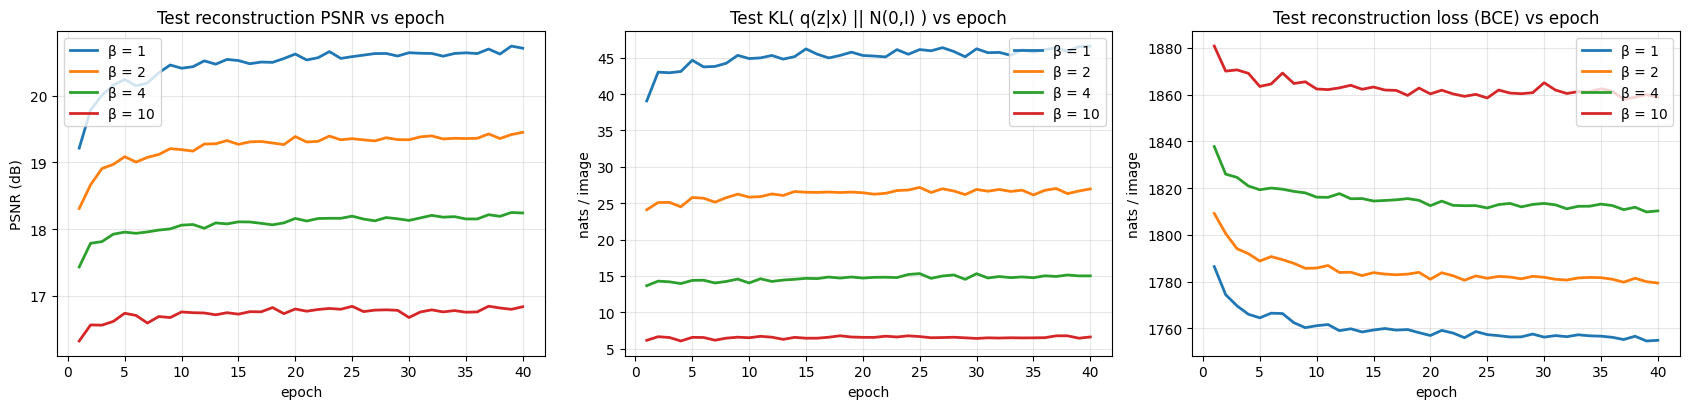

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for beta in CFG["betas"]:
    h = vae_hist[beta]
    ax[0].plot(h["epoch"], h["test_psnr"], label=f"β = {beta}", lw=2)
    ax[1].plot(h["epoch"], h["test_kl"], label=f"β = {beta}", lw=2)
    ax[2].plot(h["epoch"], h["test_recon"], label=f"β = {beta}", lw=2)
ax[0].set_title("Test reconstruction PSNR vs epoch"); ax[0].set_ylabel("PSNR (dB)")
ax[1].set_title("Test KL( q(z|x) || N(0,I) ) vs epoch"); ax[1].set_ylabel("nats / image")
ax[2].set_title("Test reconstruction loss (BCE) vs epoch"); ax[2].set_ylabel("nats / image")
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend()
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vae_psnr_vs_epoch.png", dpi=150, bbox_inches="tight")
plt.show()

#### FID, precision and recall for different β

Samples are generated by decoding `z ~ N(0, I)`. Each FID is the mean +- std over independent sampling rounds
of `N_FID` images.

In [11]:
vae_rows, vae_samples = [], {}
for beta in CFG["betas"]:
    m = vae_models[beta]
    metrics, first = evaluate_generator(lambda n, m=m: sample_vae(m, n))
    vae_samples[beta] = first
    h = vae_hist[beta]
    n_active, _ = active_units(m, X_test)
    t0 = time.time(); sample_vae(m, 1000); torch.cuda.synchronize(); t_sample = time.time() - t0
    row = {"β": beta,
           "Test PSNR (dB)": h["test_psnr"][-1],
           "Test KL (nats)": h["test_kl"][-1],
           "Active units (of %d)" % CFG["latent_dim"]: n_active,
           "FID": metrics["FID"], "FID std": metrics["FID_std"],
           "Precision": metrics["Precision"], "Recall": metrics["Recall"],
           "Train time (s)": vae_time[beta], "Sampling (ms / 1000 img)": 1000 * t_sample,
           "Params": count_params(m)}
    vae_rows.append(row)
    update_results(RESULTS_PATH, f"vae_beta_{beta}", {**row, "history": vae_hist[beta]})
    if beta == 1:
        save_100(vae_samples[beta], "vae_beta1")
    print(f"beta={beta:>2} | FID {metrics['FID']:.2f} +- {metrics['FID_std']:.2f} | "
          f"P {metrics['Precision']:.3f} R {metrics['Recall']:.3f} | active units {n_active}")

vae_table = pd.DataFrame(vae_rows).set_index("β")
vae_table.round(3)

beta= 1 | FID 141.50 +- 0.46 | P 0.264 R 0.002 | active units 120


beta= 2 | FID 172.82 +- 0.15 | P 0.162 R 0.000 | active units 77


beta= 4 | FID 214.61 +- 0.30 | P 0.090 R 0.000 | active units 44


beta=10 | FID 275.47 +- 0.69 | P 0.059 R 0.000 | active units 11


,Test PSNR (dB),Test KL (nats),Active units (of 128),FID,FID std,Precision,Recall,Train time (s),Sampling (ms / 1000 img),Params
β,,,,,,,,,,
1,20.711,46.593,120,141.500,0.460,0.264,0.002,365.511,24.854,2896003
2,19.450,26.963,77,172.816,0.145,0.162,0.000,371.650,24.149,2896003
4,18.243,15.016,44,214.609,0.300,0.090,0.000,385.770,24.504,2896003
10,16.838,6.619,11,275.474,0.693,0.059,0.000,390.618,25.270,2896003


#### Comparison plots: reconstruction quality vs. sample realism

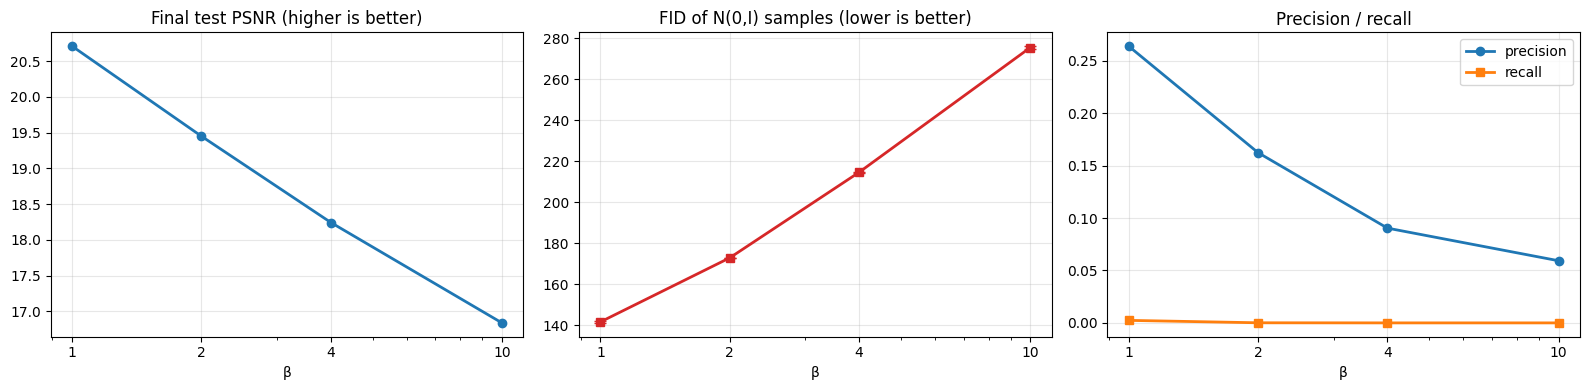

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
b = list(vae_table.index)
ax[0].plot(b, vae_table["Test PSNR (dB)"], "o-", lw=2); ax[0].set_title("Final test PSNR (higher is better)")
ax[1].errorbar(b, vae_table["FID"], yerr=vae_table["FID std"], fmt="s-", lw=2, capsize=4, color="C3")
ax[1].set_title("FID of N(0,I) samples (lower is better)")
ax[2].plot(b, vae_table["Precision"], "o-", label="precision", lw=2)
ax[2].plot(b, vae_table["Recall"], "s-", label="recall", lw=2); ax[2].legend(); ax[2].set_title("Precision / recall")
for a in ax:
    a.set_xscale("log"); a.set_xticks(b); a.set_xticklabels(b); a.set_xlabel("β"); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vae_beta_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

#### Visual comparison: reconstructions and random samples

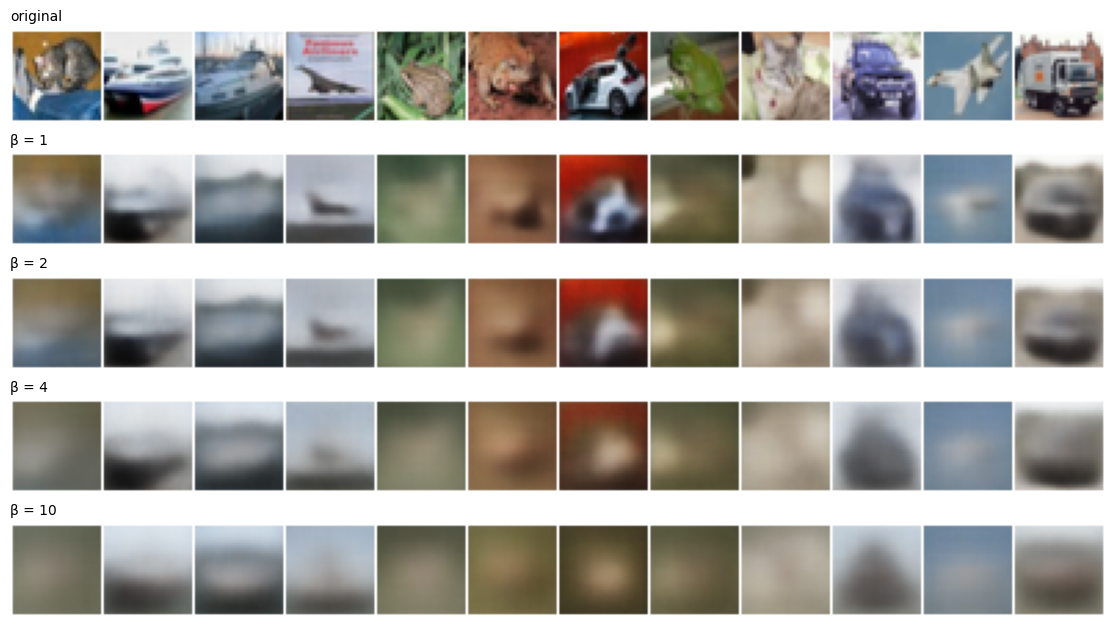

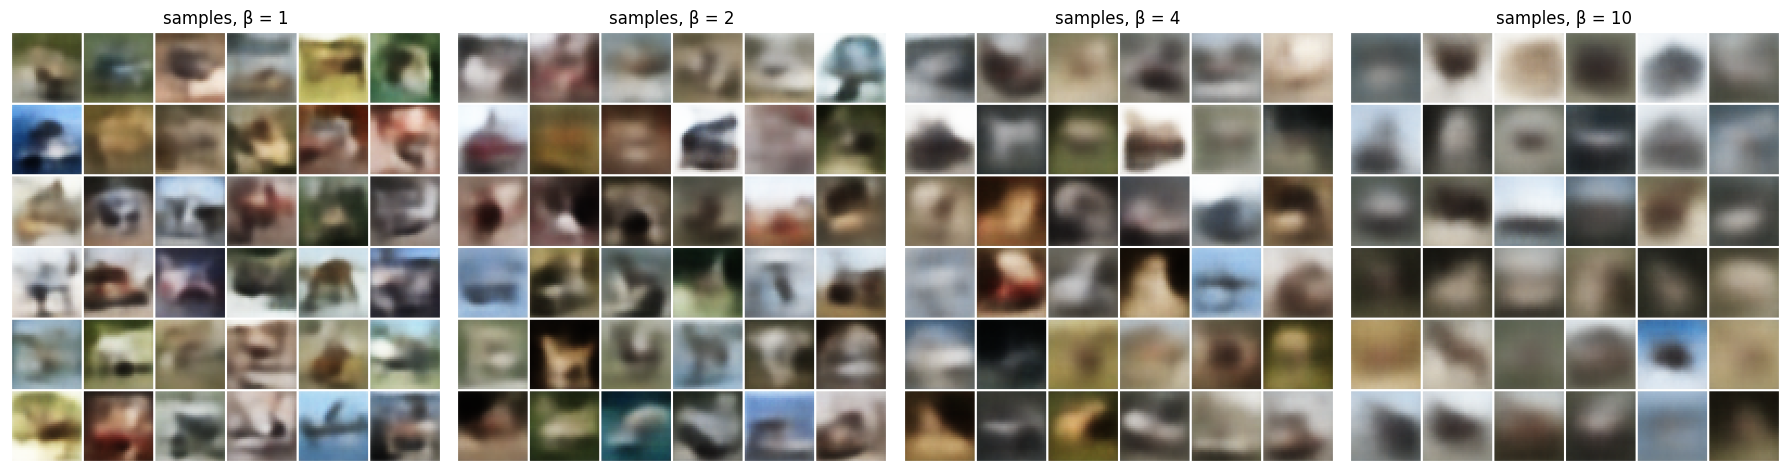

In [13]:
n_show = 12
x_show = X_test[:n_show]
rows = [x_show]
with torch.no_grad():
    for beta in CFG["betas"]:
        vae_models[beta].eval()
        rows.append(vae_models[beta].decode(vae_models[beta].encode(x_show)[0]))
labels = ["original"] + [f"β = {b}" for b in CFG["betas"]]
fig, axes = plt.subplots(len(rows), 1, figsize=(12, 1.15 * len(rows) + 0.6))
for a, r, l in zip(axes, rows, labels):
    a.imshow(to_grid(r, nrow=n_show, scale=1)); a.axis("off"); a.set_title(l, loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vae_reconstructions.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for a, beta in zip(axes, CFG["betas"]):
    a.imshow(to_grid(vae_samples[beta][:36], nrow=6, scale=2)); a.axis("off"); a.set_title(f"samples, β = {beta}")
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vae_samples_by_beta.png", dpi=150, bbox_inches="tight")
plt.show()

#### Extra: latent-space interpolation and latent traversal

*Interpolation* decodes points on the straight line between the posterior means of two test images; a smooth,
meaningful path indicates a well-organised latent space. *Traversal* varies one of the **most active latent
dimensions** while the others stay fixed at the values of a test image, showing what that dimension encodes.

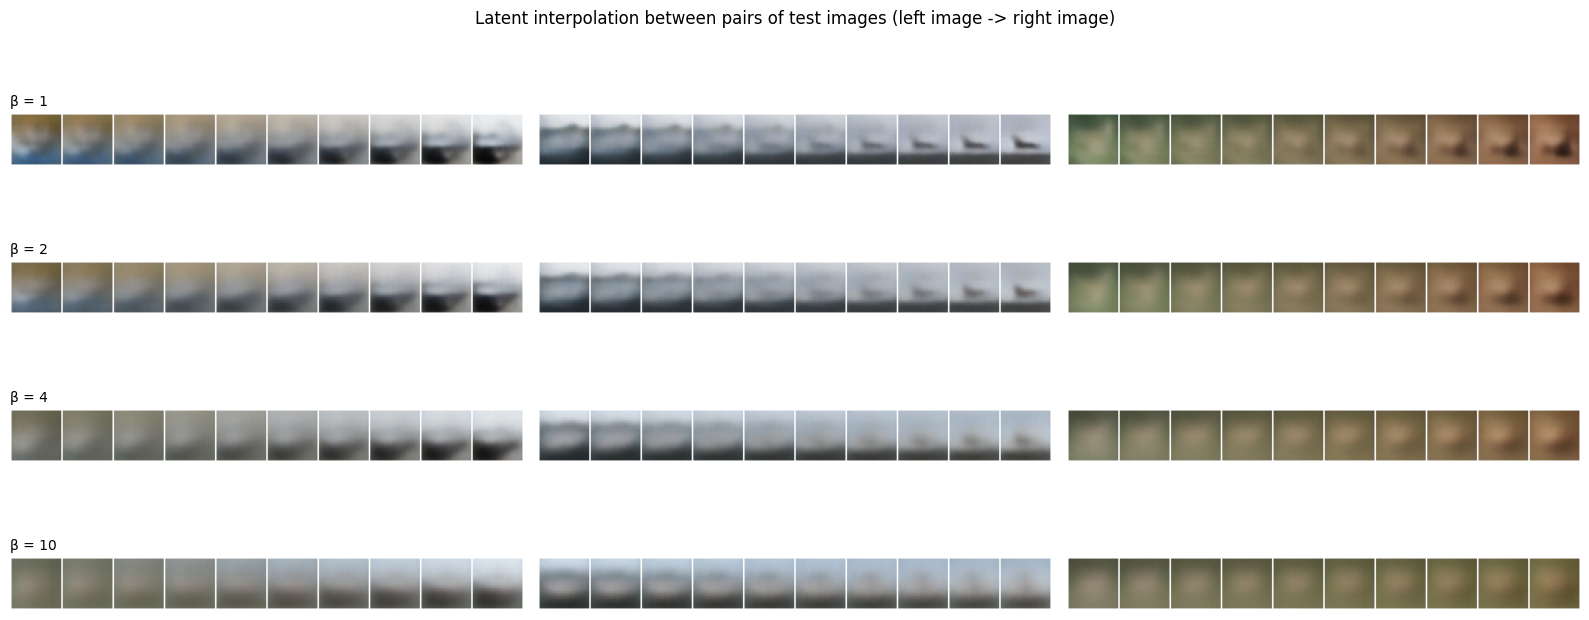

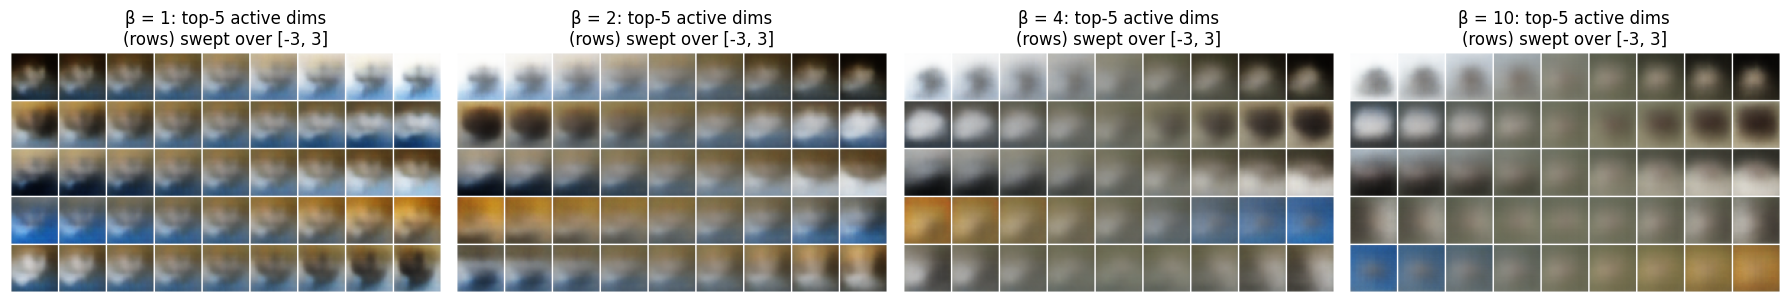

In [14]:
@torch.no_grad()
def interpolate(model, x1, x2, steps=10):
    model.eval()
    z1, z2 = model.encode(x1[None])[0], model.encode(x2[None])[0]
    a = torch.linspace(0, 1, steps, device=DEVICE)[:, None]
    return model.decode((1 - a) * z1 + a * z2)

pairs = [(0, 1), (2, 3), (4, 5)]
fig, axes = plt.subplots(len(CFG["betas"]), len(pairs), figsize=(16, 7))
for r, beta in enumerate(CFG["betas"]):
    for c, (i, j) in enumerate(pairs):
        strip = interpolate(vae_models[beta], X_test[i], X_test[j])
        axes[r, c].imshow(to_grid(strip, nrow=10)); axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(f"β = {beta}", loc="left", fontsize=10)
plt.suptitle("Latent interpolation between pairs of test images (left image -> right image)")
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vae_interpolation.png", dpi=150, bbox_inches="tight")
plt.show()


@torch.no_grad()
def traverse(model, x, dims, values):
    z0 = model.encode(x[None])[0]
    out = []
    for d in dims:
        z = z0.repeat(len(values), 1)
        z[:, d] = torch.as_tensor(values, device=DEVICE, dtype=z.dtype)
        out.append(model.decode(z))
    return torch.cat(out)

vals = np.linspace(-3, 3, 9)
fig, axes = plt.subplots(1, len(CFG["betas"]), figsize=(18, 4.6))
for a, beta in zip(axes, CFG["betas"]):
    n_act, var = active_units(vae_models[beta], X_test)
    dims = np.argsort(-var)[:5]
    a.imshow(to_grid(traverse(vae_models[beta], X_test[0], dims, vals), nrow=len(vals), scale=2))
    a.axis("off"); a.set_title(f"β = {beta}: top-5 active dims\n(rows) swept over [-3, 3]")
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vae_traversal.png", dpi=150, bbox_inches="tight")
plt.show()

#### Analysis: effect of β

All four models share the architecture, seed, optimiser and number of epochs, so every difference below is caused by β alone.

| β | Test PSNR (dB) | Test KL (nats) | Active units (of 128) | FID | Precision | Recall |
|---|---|---|---|---|---|---|
| 1 | 20.71 | 46.6 | 120 | 141.5 ± 0.5 | 0.264 | 0.002 |
| 2 | 19.45 | 27.0 | 77 | 172.8 ± 0.1 | 0.162 | 0.000 |
| 4 | 18.24 | 15.0 | 44 | 214.6 ± 0.3 | 0.090 | 0.000 |
| 10 | 16.84 | 6.6 | 11 | 275.5 ± 0.7 | 0.059 | 0.000 |

---

##### (i) Reconstruction quality (PSNR versus epoch)

**Reconstruction quality falls monotonically as β grows**: roughly 1.2-1.4 dB is lost every time β doubles
(20.71 → 19.45 → 18.24 → 16.84 dB). The PSNR curves are well separated from the first epoch and never cross, and each
curve flattens after about 10-15 epochs, so the ordering is not an artefact of unfinished training.

The reason is visible in the KL column. The objective `recon + β·KL` charges β nats for every nat of information the code
carries about the image; with a larger β the optimum moves to a code that stores **less** information
(KL falls from 46.6 to 6.6 nats), and an image cannot be reconstructed better than the information in its code allows. The
decoder then fills in the average detail, which is why the β = 10 reconstructions keep only the global colour layout.

##### (ii) Sample realism (FID)

**FID gets worse as β grows (141.5 → 172.8 → 214.6 → 275.5), and precision falls with it.** We had hedged in the
*Expected Result* cell that a larger β might improve FID because the aggregate posterior then matches the prior better;
that was **not observed** here. The more useful explanation comes from the *active units* count: at β = 1 about 120 of 128
latent dimensions carry information, at β = 10 only 11 do (posterior collapse of the other dimensions). A decoder that
receives so little information can only produce a handful of smooth, nearly identical blobs, and the Inception
features of such images are far from those of real photographs.

At β = 1 the prior-matching benefit is real but small compared with the loss of detail: the best FID of the four models is the one
with the best reconstruction. **Recall is essentially zero for every β** (0.002 at best) — the samples occupy only a small
part of the real-image manifold. Sampling noise of the FID itself is below 1 point (the ± values), so all differences between β
values are far larger than the evaluation noise.

##### (iii) What the pictures show

* **Reconstructions** (figure above): β = 1 keeps object silhouettes and colours but is soft; β = 4 and β = 10 are progressively
  smoother colour fields.
* **Random samples**: all β give blurry, texture-less blobs — the well-known behaviour of a pixel-wise likelihood on natural
  images, which predicts the *mean* of the plausible images and therefore averages away high-frequency detail. Higher β
  makes the blobs more alike each other and less colourful.
* **Interpolations** are smooth and gradual for every β, which indicates a well-organised latent space, but the intermediate
  images are as blurry as the end points. With β = 10 the two end images are already close to each other.
* **Traversals** of the most active dimensions mostly change global properties (overall brightness, hue, background layout)
  rather than object identity; the higher the β, the fewer dimensions change anything at all.

**Summary:** β controls an information-bottleneck trade-off. On CIFAR-10, with a pixel-wise likelihood, the best β of those tried
for *both* reconstruction and sampling is β = 1; larger β buys a more compact code (and a latent space with fewer redundant
dimensions) at the price of both metrics. Training time is the same for all β (about 6 min each on the local GPU).

### Part A-2: VQ-VAE with a PixelCNN prior

#### Objective

Train a **Vector-Quantised VAE** for codebook sizes `K ∈ {512, 256, 128}`, then turn it into a *generative* model by
learning an autoregressive **PixelCNN prior over the discrete latent maps**:

1. train the VQ-VAE and report the reconstruction quality (PSNR),
2. extract the discrete latent map (`8x8` indices) of every training / test image,
3. train a PixelCNN over these maps,
4. sample new latent maps with the PixelCNN (ancestral sampling),
5. decode the sampled codes into images,
6. compare **FID, PSNR and codebook quality** (usage, perplexity, dead codes) across `K`.

Expected Result

We expect to see:

* A VQ-VAE reconstructs far better than the VAE of Part A-1 because the bottleneck is a spatial `8x8` grid of
  discrete codes (`8·8·log2 K` bits) rather than one blurry 128-d vector: **PSNR in the mid-20s dB**.
* A **larger codebook reconstructs better** (higher PSNR, lower reconstruction error) because the quantiser has more
  prototypes to choose from; the improvement flattens as `K` grows because not all codes are used.
* **Codebook utilisation** is the key diagnostic: usage / perplexity should stay high (we use EMA updates and dead-code
  restarts to prevent codebook collapse), and the perplexity should be lower than `K` — close to `K` means the codes are
  used almost uniformly.
* Samples drawn with the PixelCNN prior are sharper and more object-like than VAE samples, so the **FID should be clearly
  lower than the VAE FID**. The FID is limited by the quality of the prior (a small PixelCNN on `8x8` maps), so it will
  not follow PSNR monotonically with `K`.

#### Architecture: VQ-VAE

* **Encoder:** `Conv 4x4/2 → Conv 4x4/2 → Conv 3x3 → 2 residual blocks → 1x1 conv`, mapping a `32x32x3` image to an
  `8x8x64` grid of continuous vectors `z_e`.
* **Vector quantiser:** every `z_e` is replaced by its nearest codebook vector `e_k` (`K` codes of dimension 64). The codebook
  is trained with **exponential-moving-average** updates (decay 0.99) instead of a gradient codebook loss, and the encoder
  receives the **commitment loss** `0.25 · ||z_e − sg[e]||²`. Gradients cross the quantiser with the **straight-through estimator**.
* **Dead-code restart (extra):** during the first 70 % of training, codes whose EMA usage falls below one assignment are
  re-initialised to random encoder outputs. This is a standard fix for *codebook collapse* and is what keeps
  utilisation high for `K = 512`.
* **Decoder:** the mirror image (`Conv 3x3 → 2 residual blocks → 2 × ConvTranspose 4x4/2`) with a linear output.
* **Loss:** `MSE(x, x̂) / Var(data) + 0.25 · commitment`. Inputs are in `[0, 1]`; the network internally works on `x − 0.5`.

In [15]:
class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.f = nn.Sequential(nn.ReLU(), nn.Conv2d(ch, ch, 3, 1, 1), nn.ReLU(), nn.Conv2d(ch, ch, 1))

    def forward(self, x):
        return x + self.f(x)


class VectorQuantizerEMA(nn.Module):
    def __init__(self, K, D, decay=0.99, eps=1e-5):
        super().__init__()
        self.K, self.D, self.decay, self.eps = K, D, decay, eps
        embed = torch.randn(K, D)
        self.register_buffer("embed", embed)
        self.register_buffer("embed_avg", embed.clone())
        self.register_buffer("cluster_size", torch.ones(K))
        self._flat = None

    def forward(self, z):
        B, D, H, W = z.shape
        zp = z.permute(0, 2, 3, 1).contiguous()
        flat = zp.view(-1, D)
        dist = flat.pow(2).sum(1, keepdim=True) - 2 * flat @ self.embed.t() + self.embed.pow(2).sum(1)[None]
        idx = dist.argmin(1)
        onehot = F.one_hot(idx, self.K).type(flat.dtype)
        if self.training:
            self._flat = flat.detach()
            self.cluster_size.mul_(self.decay).add_(onehot.sum(0), alpha=1 - self.decay)
            self.embed_avg.mul_(self.decay).add_(onehot.t() @ flat.detach(), alpha=1 - self.decay)
            n = self.cluster_size.sum()
            cs = (self.cluster_size + self.eps) / (n + self.K * self.eps) * n
            self.embed.copy_(self.embed_avg / cs[:, None])
        q = self.embed[idx].view_as(zp)
        commit = F.mse_loss(zp, q.detach())
        q = zp + (q - zp).detach()                                   # straight-through estimator
        probs = onehot.mean(0)
        perplexity = torch.exp(-(probs * torch.log(probs + 1e-10)).sum())
        return q.permute(0, 3, 1, 2).contiguous(), commit, idx.view(B, H, W), perplexity

    @torch.no_grad()
    def restart_dead_codes(self):
        dead = self.cluster_size < 1.0
        n_dead = int(dead.sum().item())
        if n_dead > 0 and self._flat is not None:
            pick = self._flat[torch.randint(len(self._flat), (n_dead,), device=self._flat.device)]
            self.embed[dead] = pick
            self.embed_avg[dead] = pick
            self.cluster_size[dead] = 1.0
        return n_dead


class VQVAE(nn.Module):
    def __init__(self, K, D=64, H=128):
        super().__init__()
        self.K, self.D = K, D
        self.encoder = nn.Sequential(
            nn.Conv2d(3, H, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(H, H, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(H, H, 3, 1, 1),
            ResBlock(H), ResBlock(H), nn.ReLU(),
            nn.Conv2d(H, D, 1),
        )
        self.vq = VectorQuantizerEMA(K, D)
        self.decoder = nn.Sequential(
            nn.Conv2d(D, H, 3, 1, 1),
            ResBlock(H), ResBlock(H), nn.ReLU(),
            nn.ConvTranspose2d(H, H, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(H, 3, 4, 2, 1),
        )

    def forward(self, x):
        z_e = self.encoder(x - 0.5)
        q, commit, idx, perplexity = self.vq(z_e)
        return self.decoder(q) + 0.5, commit, idx, perplexity

    @torch.no_grad()
    def encode_indices(self, x):
        self.eval()
        return self.vq(self.encoder(x - 0.5))[2]

    @torch.no_grad()
    def decode_indices(self, idx):
        self.eval()
        q = self.vq.embed[idx].permute(0, 3, 1, 2).contiguous()
        return (self.decoder(q) + 0.5).clamp(0, 1)

print("parameters (K=512):", count_params(VQVAE(512)))

parameters (K=512): 1423043


#### Training and evaluation helpers

In [16]:
@torch.no_grad()
def evaluate_vqvae(model, X, bs=1000):
    model.eval()
    psnr, mse, counts = [], 0.0, torch.zeros(model.K, device=DEVICE)
    for i in range(0, len(X), bs):
        x = X[i:i + bs]
        x_hat, _, idx, _ = model(x)
        x_hat = x_hat.clamp(0, 1)
        psnr.append(psnr_per_image(x, x_hat))
        mse += F.mse_loss(x_hat, x, reduction="sum").item()
        counts += torch.bincount(idx.flatten(), minlength=model.K).float()
    p = counts / counts.sum()
    perplexity = torch.exp(-(p * torch.log(p + 1e-10)).sum()).item()
    return {"psnr": torch.cat(psnr).mean().item(), "mse": mse / X.numel(),
            "usage": (counts > 0).float().mean().item(), "perplexity": perplexity,
            "dead_codes": int((counts == 0).sum().item()), "counts": counts.cpu().numpy()}


def train_vqvae(K, epochs, seed=SEED):
    set_seed(seed)
    model = VQVAE(K, CFG["vq_dim"]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["vq_lr"])
    hist = {"epoch": [], "test_psnr": [], "test_mse": [], "usage": [], "perplexity": [], "train_loss": []}
    t0, step = time.time(), 0
    for ep in range(1, epochs + 1):
        model.train()
        total, n, restarted = 0.0, 0, 0
        for x in batches(X_train, CFG["batch_size"]):
            x_hat, commit, _, _ = model(x)
            loss = F.mse_loss(x_hat, x) / DATA_VAR + 0.25 * commit
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            step += 1
            if ep <= 0.7 * epochs and step % 50 == 0:               # dead-code restarts (early training only)
                restarted += model.vq.restart_dead_codes()
            total += loss.item() * len(x)
            n += len(x)
        ev = evaluate_vqvae(model, X_test)
        hist["epoch"].append(ep); hist["test_psnr"].append(ev["psnr"]); hist["test_mse"].append(ev["mse"])
        hist["usage"].append(ev["usage"]); hist["perplexity"].append(ev["perplexity"]); hist["train_loss"].append(total / n)
        if ep == 1 or ep % 5 == 0 or ep == epochs:
            print(f"K={K:>3} | epoch {ep:>3}/{epochs} | train loss {total / n:7.4f} | test PSNR {ev['psnr']:6.2f} dB | "
                  f"usage {100 * ev['usage']:5.1f} % | perplexity {ev['perplexity']:6.1f} | restarted {restarted}")
    return model, hist, time.time() - t0

#### Train the VQ-VAE for K = 512, 256, 128

Only the codebook size changes between the three runs (same seed, optimiser, batch size and number of epochs).

In [17]:
vq_models, vq_hist, vq_time = {}, {}, {}
for K in CFG["ks"]:
    vq_models[K], vq_hist[K], vq_time[K] = train_vqvae(K, CFG["vq_epochs"])
    print(f"--> K={K} trained in {vq_time[K]:.0f} s\n")

K=512 | epoch   1/40 | train loss  0.2639 | test PSNR  22.33 dB | usage  94.9 % | perplexity  279.2 | restarted 844


K=512 | epoch   5/40 | train loss  0.0951 | test PSNR  24.60 dB | usage 100.0 % | perplexity  446.3 | restarted 0


K=512 | epoch  10/40 | train loss  0.1050 | test PSNR  24.99 dB | usage 100.0 % | perplexity  423.7 | restarted 0


K=512 | epoch  15/40 | train loss  0.1040 | test PSNR  24.85 dB | usage 100.0 % | perplexity  410.6 | restarted 0


K=512 | epoch  20/40 | train loss  0.1016 | test PSNR  25.26 dB | usage 100.0 % | perplexity  412.4 | restarted 0


K=512 | epoch  25/40 | train loss  0.0994 | test PSNR  25.22 dB | usage 100.0 % | perplexity  407.5 | restarted 0


... (17 outputs left out)

K=128 | epoch  25/40 | train loss  0.1227 | test PSNR  24.12 dB | usage 100.0 % | perplexity  108.9 | restarted 0


K=128 | epoch  30/40 | train loss  0.1204 | test PSNR  24.24 dB | usage 100.0 % | perplexity  109.6 | restarted 0


K=128 | epoch  35/40 | train loss  0.1183 | test PSNR  24.29 dB | usage 100.0 % | perplexity  109.4 | restarted 0


K=128 | epoch  40/40 | train loss  0.1162 | test PSNR  24.29 dB | usage 100.0 % | perplexity  111.3 | restarted 0
--> K=128 trained in 739 s



#### VQ-VAE reconstruction quality

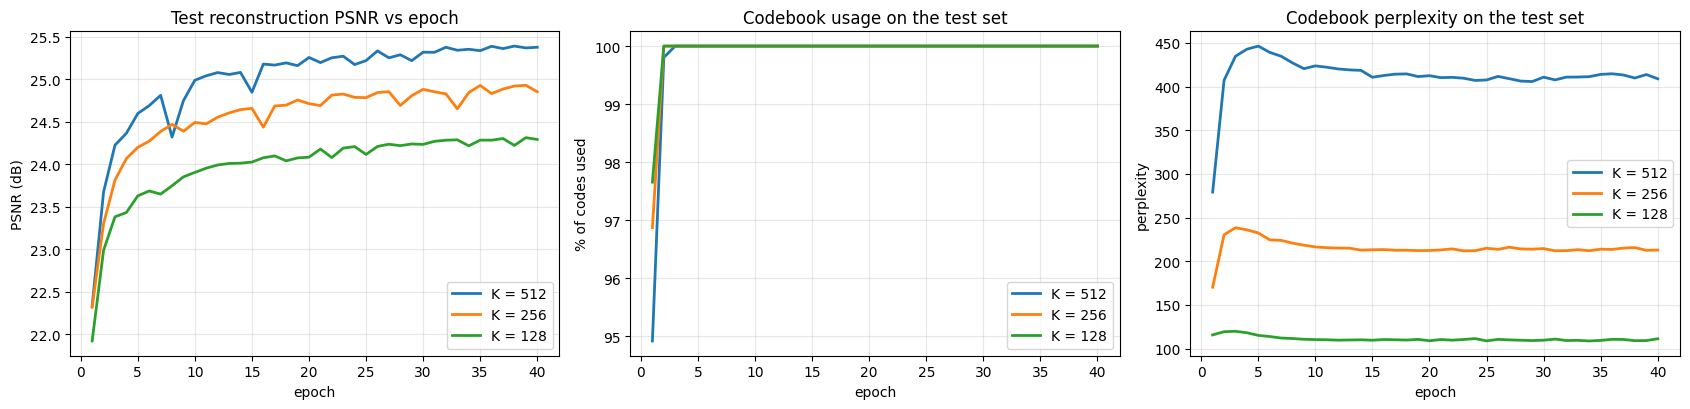

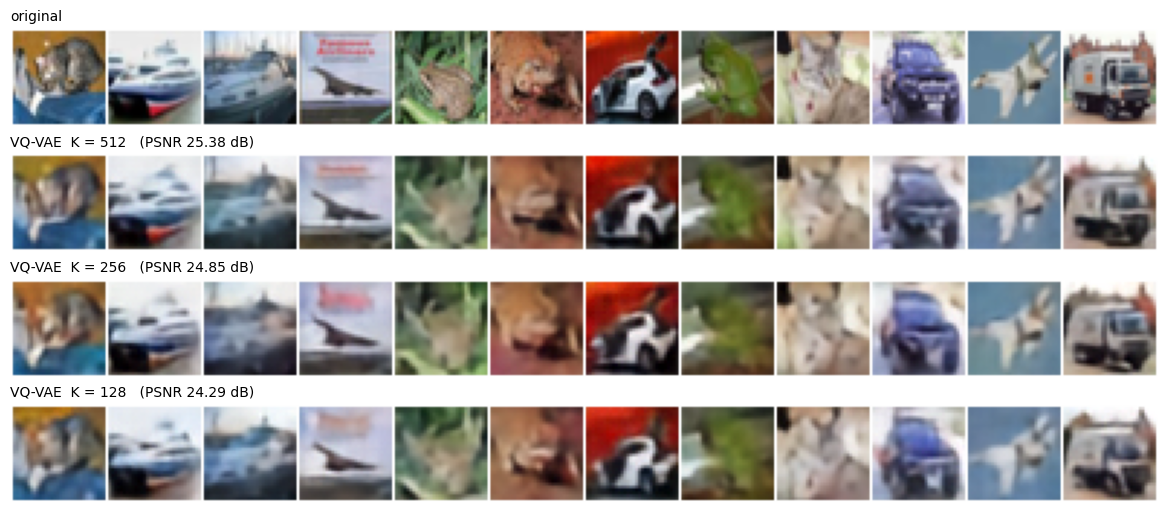

In [18]:
vq_eval = {K: evaluate_vqvae(vq_models[K], X_test) for K in CFG["ks"]}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for K in CFG["ks"]:
    h = vq_hist[K]
    ax[0].plot(h["epoch"], h["test_psnr"], lw=2, label=f"K = {K}")
    ax[1].plot(h["epoch"], [100 * u for u in h["usage"]], lw=2, label=f"K = {K}")
    ax[2].plot(h["epoch"], h["perplexity"], lw=2, label=f"K = {K}")
ax[0].set_title("Test reconstruction PSNR vs epoch"); ax[0].set_ylabel("PSNR (dB)")
ax[1].set_title("Codebook usage on the test set"); ax[1].set_ylabel("% of codes used")
ax[2].set_title("Codebook perplexity on the test set"); ax[2].set_ylabel("perplexity")
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend()
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vqvae_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

n_show = 12
rows = [X_test[:n_show]] + [vq_models[K](X_test[:n_show])[0].clamp(0, 1).detach() for K in CFG["ks"]]
labels = ["original"] + [f"VQ-VAE  K = {K}   (PSNR {vq_eval[K]['psnr']:.2f} dB)" for K in CFG["ks"]]
fig, axes = plt.subplots(len(rows), 1, figsize=(12, 1.15 * len(rows) + 0.6))
for a, r, l in zip(axes, rows, labels):
    a.imshow(to_grid(r, nrow=n_show)); a.axis("off"); a.set_title(l, loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vqvae_reconstructions.png", dpi=150, bbox_inches="tight")
plt.show()

#### Codebook quality (extra)

Left: the sorted usage histogram of every code on the test set (a flat curve means all codes are used evenly; a steep
drop means a few codes dominate). Right: the 64 most-used codes of the `K = 256` model, *visualised* by decoding an `8x8`
map filled with that single code — each tile is the texture that code stands for.

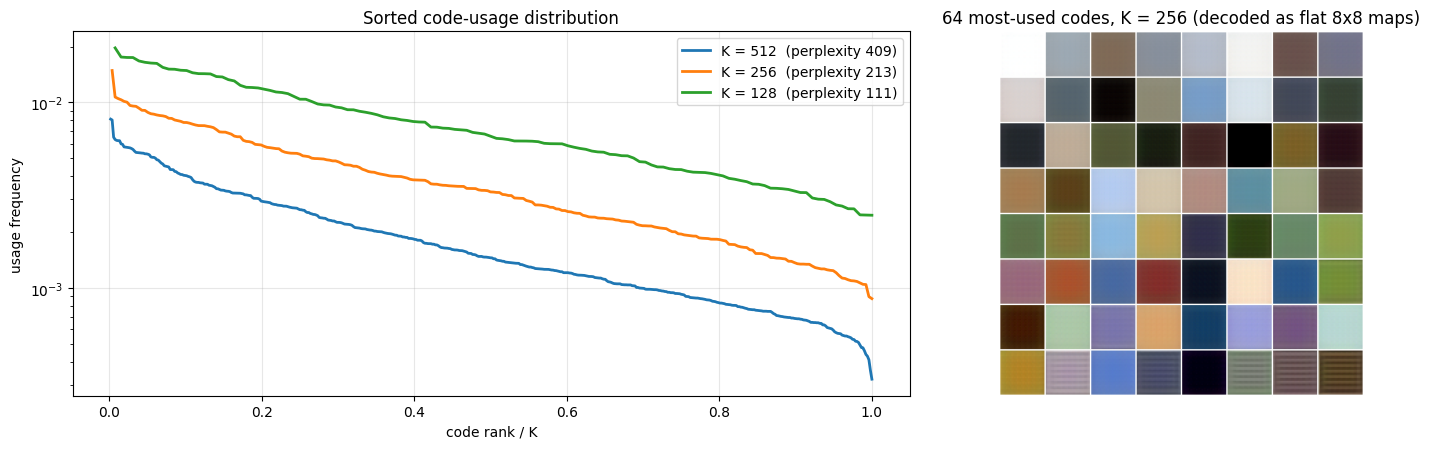

,usage (%),dead codes,perplexity,perplexity / K
512,100.0,0.0,408.923,0.799
256,100.0,0.0,212.846,0.831
128,100.0,0.0,111.284,0.869


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
for K in CFG["ks"]:
    c = np.sort(vq_eval[K]["counts"])[::-1]
    ax[0].plot(np.arange(1, K + 1) / K, c / c.sum(), lw=2, label=f"K = {K}  (perplexity {vq_eval[K]['perplexity']:.0f})")
ax[0].set_yscale("log"); ax[0].set_xlabel("code rank / K"); ax[0].set_ylabel("usage frequency")
ax[0].set_title("Sorted code-usage distribution"); ax[0].grid(alpha=0.3); ax[0].legend()

K_vis = 256 if 256 in vq_models else CFG["ks"][0]
top = np.argsort(-vq_eval[K_vis]["counts"])[:64]
tiles = vq_models[K_vis].decode_indices(torch.as_tensor(top, device=DEVICE).view(-1, 1, 1).repeat(1, 8, 8))
ax[1].imshow(to_grid(tiles, nrow=8, scale=2)); ax[1].axis("off")
ax[1].set_title(f"64 most-used codes, K = {K_vis} (decoded as flat 8x8 maps)")
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vqvae_codebook_quality.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({K: {"usage (%)": 100 * vq_eval[K]["usage"], "dead codes": vq_eval[K]["dead_codes"],
                  "perplexity": vq_eval[K]["perplexity"], "perplexity / K": vq_eval[K]["perplexity"] / K}
              for K in CFG["ks"]}).T.round(3)

#### Extract the discrete latent maps

Each image becomes an `8x8` map of integers in `[0, K)` — the data the PixelCNN is trained on (`64` tokens per image).

In [20]:
@torch.no_grad()
def extract_latents(model, X, bs=1000):
    return torch.cat([model.encode_indices(X[i:i + bs]) for i in range(0, len(X), bs)])

latents_train, latents_test = {}, {}
for K in CFG["ks"]:
    latents_train[K] = extract_latents(vq_models[K], X_train)
    latents_test[K] = extract_latents(vq_models[K], X_test)
    print(f"K={K:>3}: train latents {tuple(latents_train[K].shape)} | test latents {tuple(latents_test[K].shape)} | "
          f"index range [{latents_train[K].min().item()}, {latents_train[K].max().item()}]")

print("\nExample 8x8 latent map of the first test image (K=256):")
print(latents_test[256][0].cpu().numpy() if 256 in latents_test else latents_test[CFG['ks'][0]][0].cpu().numpy())

K=512: train latents (50000, 8, 8) | test latents (10000, 8, 8) | index range [0, 511]


K=256: train latents (50000, 8, 8) | test latents (10000, 8, 8) | index range [0, 255]


K=128: train latents (50000, 8, 8) | test latents (10000, 8, 8) | index range [0, 127]

Example 8x8 latent map of the first test image (K=256):
[[125  85 125  52 125 170 125 217]
 [ 96 125 164 117  22   7 184  93]
 [ 65  85 197 150 136  40  22   1]
 [ 94  34 238 122 195  54 211  34]
 [ 89 160 164 232 255 244  99 131]
 [110 141 100  73 164  41 146 172]
 [249  24 159  22 149 104 147 202]
 [249 180 180 180  90  22 144 204]]


#### PixelCNN prior over the latent maps

A PixelCNN factorises the distribution of a latent map as `p(c) = Π_i p(c_i | c_<i)` in raster-scan order, using **masked
convolutions** so that position `i` only sees positions above and to the left of it.

* The `K` code indices are embedded into 64-d vectors; the first layer is a `7x7` **mask-A** convolution (does not see the
  current position), followed by 8 residual blocks built from `1x1 → 3x3 mask-B → 1x1` convolutions (mask B may see the
  current feature, never the future ones), and a `1x1` head that outputs `K` logits per position.
* Trained with cross-entropy (negative log-likelihood); we report it in nats per latent map and in **bits per code**
  and compare it with the uniform prior `log2 K`.
* Sampling is ancestral: positions are filled one at a time in raster order, each drawn from the softmax of the logits.

In [21]:
class MaskedConv2d(nn.Conv2d):
    def __init__(self, mask_type, *args, **kwargs):
        super().__init__(*args, **kwargs)
        kh, kw = self.kernel_size
        mask = torch.ones_like(self.weight)
        mask[:, :, kh // 2, kw // 2 + (mask_type == "B"):] = 0       # right of centre (and centre for type A)
        mask[:, :, kh // 2 + 1:] = 0                                 # all rows below
        self.register_buffer("mask", mask)

    def forward(self, x):
        return F.conv2d(x, self.weight * self.mask, self.bias, self.stride, self.padding)


class PixelCNNBlock(nn.Module):
    def __init__(self, h):
        super().__init__()
        self.net = nn.Sequential(
            nn.ReLU(), nn.Conv2d(h, h // 2, 1),
            nn.ReLU(), MaskedConv2d("B", h // 2, h // 2, 3, padding=1),
            nn.ReLU(), nn.Conv2d(h // 2, h, 1),
        )

    def forward(self, x):
        return x + self.net(x)


class PixelCNN(nn.Module):
    def __init__(self, K, emb=64, h=128, n_blocks=8):
        super().__init__()
        self.K = K
        self.embed = nn.Embedding(K, emb)
        self.inp = MaskedConv2d("A", emb, h, 7, padding=3)
        self.blocks = nn.Sequential(*[PixelCNNBlock(h) for _ in range(n_blocks)])
        self.out = nn.Sequential(nn.ReLU(), nn.Conv2d(h, h, 1), nn.ReLU(), nn.Conv2d(h, K, 1))

    def forward(self, idx):                                         # idx: B x H x W (long)
        x = self.embed(idx).permute(0, 3, 1, 2)
        return self.out(self.blocks(self.inp(x)))                   # B x K x H x W logits


@torch.no_grad()
def sample_pixelcnn(model, n, H=8, W=8, temperature=1.0, bs=1000):
    model.eval()
    out = []
    for s in range(0, n, bs):
        m = min(bs, n - s)
        x = torch.zeros(m, H, W, dtype=torch.long, device=DEVICE)
        for i in range(H):
            for j in range(W):
                logits = model(x)[:, :, i, j] / temperature
                x[:, i, j] = torch.multinomial(F.softmax(logits, dim=1), 1).squeeze(1)
        out.append(x)
    return torch.cat(out)


@torch.no_grad()
def pixelcnn_nll(model, latents, bs=1000):
    # mean negative log-likelihood in nats per code (position)
    model.eval()
    tot = 0.0
    for i in range(0, len(latents), bs):
        z = latents[i:i + bs]
        tot += F.cross_entropy(model(z), z, reduction="sum").item()
    return tot / latents.numel()


def train_pixelcnn(K, epochs, seed=SEED):
    set_seed(seed)
    model = PixelCNN(K).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["pix_lr"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = {"epoch": [], "train_nll": [], "test_nll": []}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        tot, n = 0.0, 0
        for z in batches(latents_train[K], 128):
            loss = F.cross_entropy(model(z), z)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item() * z.numel()
            n += z.numel()
        sched.step()
        hist["epoch"].append(ep); hist["train_nll"].append(tot / n); hist["test_nll"].append(pixelcnn_nll(model, latents_test[K]))
        if ep == 1 or ep % 5 == 0 or ep == epochs:
            print(f"K={K:>3} | epoch {ep:>3}/{epochs} | train NLL {tot / n:.4f} nats/code | "
                  f"test NLL {hist['test_nll'][-1]:.4f} nats/code (uniform prior: {math.log(K):.4f})")
    return model, hist, time.time() - t0

print("PixelCNN parameters (K=512):", count_params(PixelCNN(512)))

PixelCNN parameters (K=512): 944896


#### Train the PixelCNN for each codebook size

K=512 | epoch   1/40 | train NLL 5.3845 nats/code | test NLL 5.1205 nats/code (uniform prior: 6.2383)


K=512 | epoch   5/40 | train NLL 4.8168 nats/code | test NLL 4.8551 nats/code (uniform prior: 6.2383)


K=512 | epoch  10/40 | train NLL 4.7094 nats/code | test NLL 4.8140 nats/code (uniform prior: 6.2383)


K=512 | epoch  15/40 | train NLL 4.6534 nats/code | test NLL 4.8123 nats/code (uniform prior: 6.2383)


K=512 | epoch  20/40 | train NLL 4.6125 nats/code | test NLL 4.8209 nats/code (uniform prior: 6.2383)


K=512 | epoch  25/40 | train NLL 4.5796 nats/code | test NLL 4.8327 nats/code (uniform prior: 6.2383)


... (17 outputs left out)

K=128 | epoch  25/40 | train NLL 3.6007 nats/code | test NLL 3.8223 nats/code (uniform prior: 4.8520)


K=128 | epoch  30/40 | train NLL 3.5785 nats/code | test NLL 3.8335 nats/code (uniform prior: 4.8520)


K=128 | epoch  35/40 | train NLL 3.5634 nats/code | test NLL 3.8405 nats/code (uniform prior: 4.8520)


K=128 | epoch  40/40 | train NLL 3.5570 nats/code | test NLL 3.8435 nats/code (uniform prior: 4.8520)
--> K=128 PixelCNN trained in 519 s



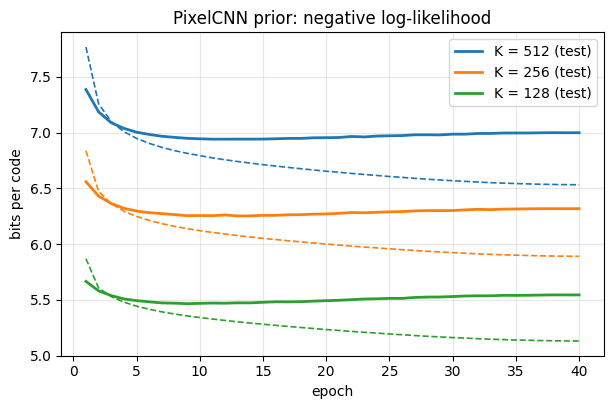

In [22]:
pix_models, pix_hist, pix_time = {}, {}, {}
for K in CFG["ks"]:
    pix_models[K], pix_hist[K], pix_time[K] = train_pixelcnn(K, CFG["pix_epochs"])
    print(f"--> K={K} PixelCNN trained in {pix_time[K]:.0f} s\n")

plt.figure(figsize=(7, 4.2))
for K in CFG["ks"]:
    plt.plot(pix_hist[K]["epoch"], np.array(pix_hist[K]["test_nll"]) / math.log(2), lw=2, label=f"K = {K} (test)")
    plt.plot(pix_hist[K]["epoch"], np.array(pix_hist[K]["train_nll"]) / math.log(2), "--", lw=1.2, color=plt.gca().lines[-1].get_color())
plt.xlabel("epoch"); plt.ylabel("bits per code"); plt.title("PixelCNN prior: negative log-likelihood")
plt.grid(alpha=0.3); plt.legend()
plt.savefig(f"{RES_DIR}/figures/pixelcnn_nll.png", dpi=150, bbox_inches="tight")
plt.show()

#### Sample new latent codes with the PixelCNN and generate images

Sampled latent maps are decoded by the corresponding VQ-VAE decoder. We evaluate FID / precision / recall exactly as for the
VAEs and time the complete generation pipeline (latent sampling + decoding).

In [23]:
def generate_vq(K, n, temperature=1.0):
    codes = sample_pixelcnn(pix_models[K], n, temperature=temperature)
    return torch.cat([vq_models[K].decode_indices(codes[i:i + 1000]) for i in range(0, n, 1000)])

vq_rows, vq_samples = [], {}
for K in CFG["ks"]:
    metrics, first = evaluate_generator(lambda n, K=K: generate_vq(K, n))
    vq_samples[K] = first
    torch.cuda.synchronize(); t0 = time.time(); generate_vq(K, 1000); torch.cuda.synchronize(); t_gen = time.time() - t0
    ev = vq_eval[K]
    row = {"K": K, "Test PSNR (dB)": ev["psnr"], "Test MSE": ev["mse"],
           "Codebook usage (%)": 100 * ev["usage"], "Perplexity": ev["perplexity"], "Dead codes": ev["dead_codes"],
           "PixelCNN test NLL (bits/code)": pix_hist[K]["test_nll"][-1] / math.log(2),
           "FID": metrics["FID"], "FID std": metrics["FID_std"],
           "Precision": metrics["Precision"], "Recall": metrics["Recall"],
           "Train time VQ-VAE (s)": vq_time[K], "Train time PixelCNN (s)": pix_time[K],
           "Generation (s / 1000 img)": t_gen,
           "Params VQ-VAE": count_params(vq_models[K]), "Params PixelCNN": count_params(pix_models[K])}
    vq_rows.append(row)
    update_results(RESULTS_PATH, f"vqvae_K_{K}", {**row, "history": vq_hist[K], "pixelcnn_history": pix_hist[K]})
    if K == 256:
        save_100(vq_samples[K], "vqvae_k256")
    print(f"K={K:>3} | PSNR {ev['psnr']:.2f} dB | FID {metrics['FID']:.2f} +- {metrics['FID_std']:.2f} | "
          f"P {metrics['Precision']:.3f} R {metrics['Recall']:.3f} | {t_gen:.1f} s / 1000 images")

vq_table = pd.DataFrame(vq_rows).set_index("K")
vq_table.round(3)

K=512 | PSNR 25.38 dB | FID 78.42 +- 0.39 | P 0.537 R 0.116 | 5.0 s / 1000 images


K=256 | PSNR 24.85 dB | FID 80.40 +- 0.40 | P 0.555 R 0.107 | 4.9 s / 1000 images


K=128 | PSNR 24.29 dB | FID 79.02 +- 0.52 | P 0.559 R 0.099 | 4.7 s / 1000 images


,Test PSNR (dB),Test MSE,Codebook usage (%),Perplexity,Dead codes,PixelCNN test NLL (bits/code),FID,FID std,Precision,Recall,Train time VQ-VAE (s),Train time PixelCNN (s),Generation (s / 1000 img),Params VQ-VAE,Params PixelCNN
K,,,,,,,,,,,,,,,
512,25.378,0.003,100.0,408.923,0,7.000,78.425,0.393,0.537,0.116,793.068,620.470,4.997,1423043,944896
256,24.855,0.004,100.0,212.846,0,6.319,80.396,0.398,0.555,0.107,751.350,551.448,4.910,1423043,895488
128,24.293,0.004,100.0,111.284,0,5.545,79.020,0.524,0.559,0.099,738.625,519.109,4.741,1423043,870784


#### Generated samples from the PixelCNN prior

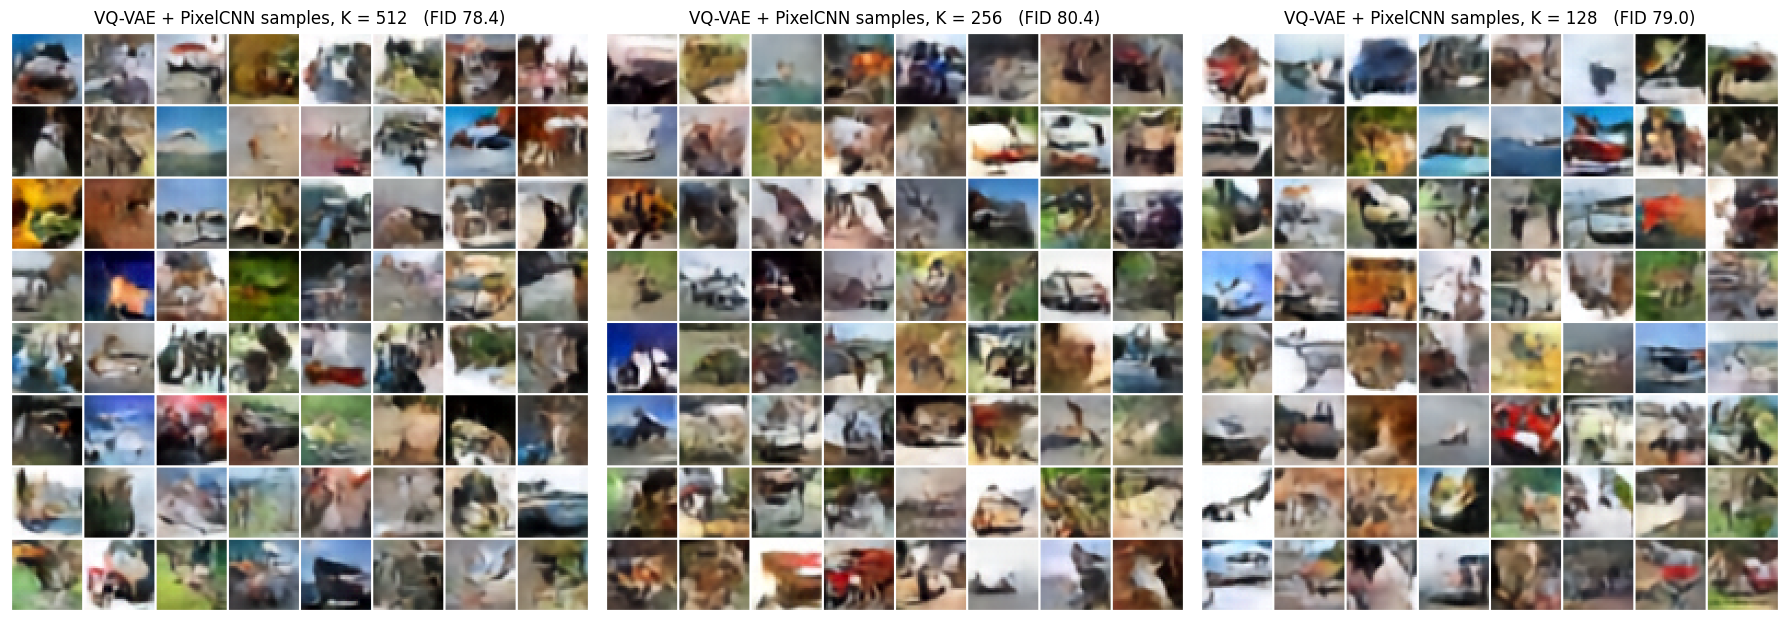

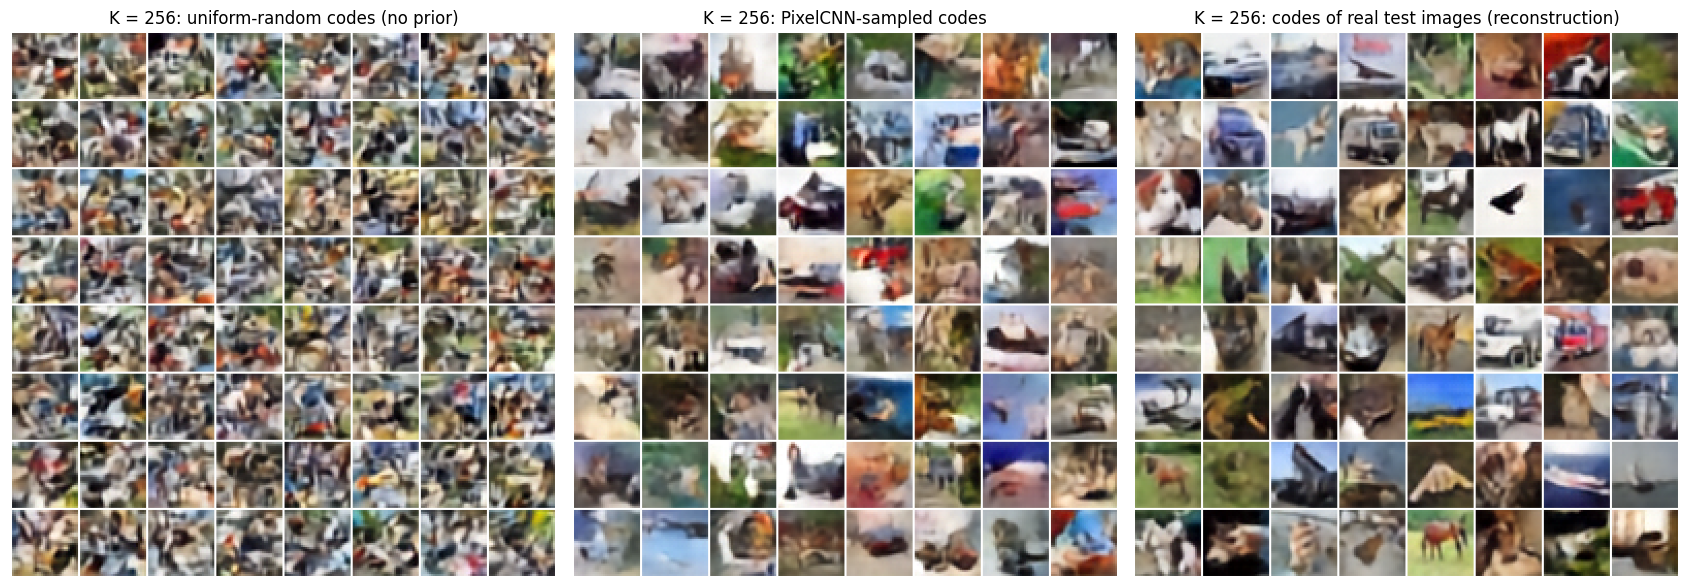

In [24]:
fig, axes = plt.subplots(1, len(CFG["ks"]), figsize=(6 * len(CFG["ks"]), 6.2))
for a, K in zip(axes, CFG["ks"]):
    a.imshow(to_grid(vq_samples[K][:64], nrow=8, scale=2)); a.axis("off")
    a.set_title(f"VQ-VAE + PixelCNN samples, K = {K}   (FID {vq_table.loc[K, 'FID']:.1f})")
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vqvae_samples.png", dpi=150, bbox_inches="tight")
plt.show()

# extra: what does the PixelCNN add?  uniform-random codes vs PixelCNN codes vs the codes of real images
K = 256 if 256 in vq_models else CFG["ks"][0]
rand_codes = torch.randint(0, K, (64, 8, 8), device=DEVICE)
imgs = [vq_models[K].decode_indices(rand_codes),
        vq_models[K].decode_indices(sample_pixelcnn(pix_models[K], 64)),
        vq_models[K].decode_indices(latents_test[K][:64])]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8))
for a, im, t in zip(axes, imgs, ["uniform-random codes (no prior)", "PixelCNN-sampled codes", "codes of real test images (reconstruction)"]):
    a.imshow(to_grid(im, nrow=8, scale=2)); a.axis("off"); a.set_title(f"K = {K}: {t}")
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vqvae_prior_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

#### Comparison across K: FID, PSNR and codebook quality

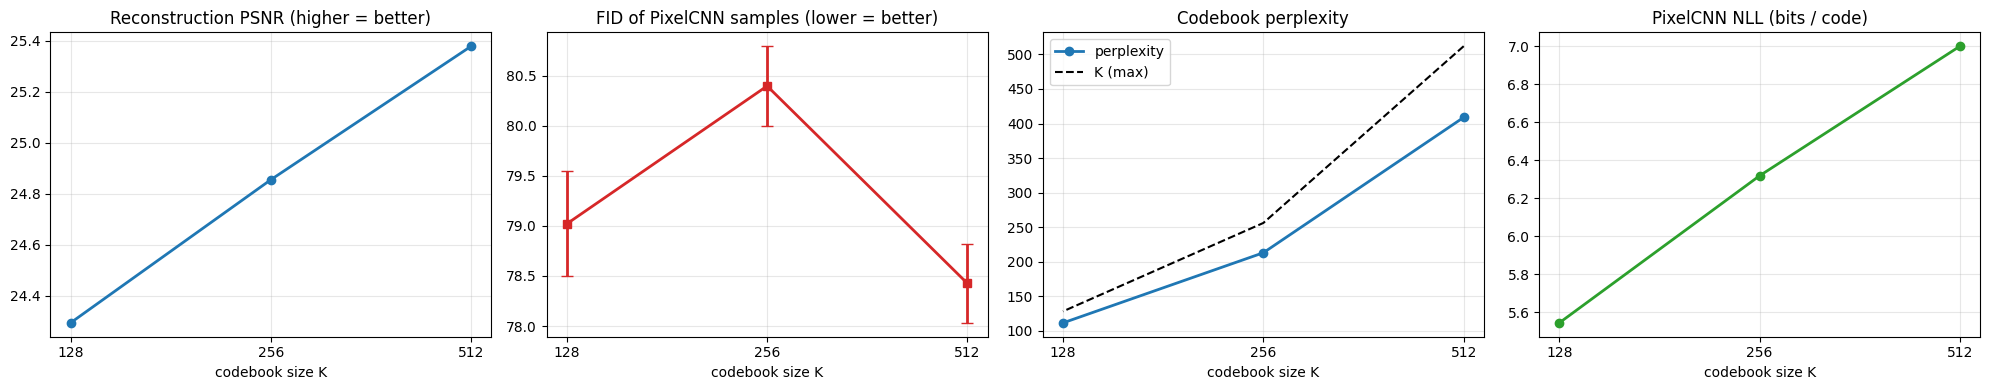

In [25]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ks = list(vq_table.index)
ax[0].plot(ks, vq_table["Test PSNR (dB)"], "o-", lw=2); ax[0].set_title("Reconstruction PSNR (higher = better)")
ax[1].errorbar(ks, vq_table["FID"], yerr=vq_table["FID std"], fmt="s-", lw=2, capsize=4, color="C3"); ax[1].set_title("FID of PixelCNN samples (lower = better)")
ax[2].plot(ks, vq_table["Perplexity"], "o-", lw=2, label="perplexity"); ax[2].plot(ks, ks, "k--", label="K (max)"); ax[2].legend(); ax[2].set_title("Codebook perplexity")
ax[3].plot(ks, vq_table["PixelCNN test NLL (bits/code)"], "o-", lw=2, color="C2"); ax[3].set_title("PixelCNN NLL (bits / code)")
for a in ax:
    a.set_xscale("log", base=2); a.set_xticks(ks); a.set_xticklabels(ks); a.set_xlabel("codebook size K"); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/vqvae_k_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

#### Analysis: effect of the codebook size K

All three VQ-VAEs have the same architecture except for the number of codebook vectors; each has its own PixelCNN prior
with the same architecture and training schedule.

| K | Test PSNR (dB) | Usage | Perplexity | Perplexity / K | PixelCNN test NLL (bits/code) | uniform prior (bits) | FID | Precision | Recall |
|---|---|---|---|---|---|---|---|---|---|
| 512 | 25.38 | 100 % | 409 | 0.80 | 7.00 | 9 | 78.4 ± 0.4 | 0.537 | 0.116 |
| 256 | 24.85 | 100 % | 213 | 0.83 | 6.32 | 8 | 80.4 ± 0.4 | 0.555 | 0.107 |
| 128 | 24.29 | 100 % | 111 | 0.87 | 5.54 | 7 | 79.0 ± 0.5 | 0.559 | 0.099 |

---

##### (i) Reconstruction quality

**A larger codebook reconstructs better**: PSNR rises 24.29 → 24.85 → 25.38 dB for K = 128 → 256 → 512, roughly
0.5 dB per doubling. The gain is modest, as expected: the information content of the `8x8` code is `64·log2 K` bits
(448 / 512 / 576 bits against 24,576 bits of raw 8-bit RGB), so every doubling adds only 64 bits. All three
models are about **4-5 dB better than the best β-VAE** (20.71 dB) even though their code is much smaller in bits, because
a **spatial** grid of discrete codes preserves local structure that a single global Gaussian vector cannot.

##### (ii) Codebook quality

* **No codebook collapse.** All three codebooks end with 100 % usage and no dead codes. Randomly initialised codes are easily left unused,
  so the dead-code restart (844 codes re-initialised during the first epoch of K = 512, none once training settled) together with
  the EMA update is what keeps every code alive.
* **Perplexity** (the effective number of codes) is 80-87 % of K and *the ratio improves slightly as K shrinks*: a small codebook
  is used more evenly. The sorted-usage plot is a gently sloping line on a log axis — the most used code appears about 8 (K = 128) to 25 (K = 512) times more often
  than the least used one — i.e. no code dominates and no code is wasted.
* The most-used codes, decoded as flat maps, are **plain colours** (greys, browns, blues, greens, skin tones), with a few
  weakly textured ones. That is what 4x4-pixel patches of natural images mostly are; edges and textures arise from *combinations*
  of neighbouring codes.

##### (iii) Sample realism (PixelCNN prior)

* The PixelCNN compresses the latent maps to **7.00 / 6.32 / 5.54 bits per code** against `log2 K` = 9 / 8 / 7 for a uniform
  prior, i.e. it removes about 2 bits (22-29 %) of every code by exploiting spatial correlation. Test NLL is higher than train NLL
  (e.g. 4.85 vs 4.53 nats for K = 512), a mild generalisation gap that shows the prior is starting to fit the training latents.
* **The prior is essential**: the ablation figure shows that decoding *uniformly random* codes gives incoherent texture noise,
  decoding *PixelCNN-sampled* codes gives coherent scene layouts (sky, ground, vehicles, animals), and decoding the codes of *real*
  images gives the sharpest pictures. The remaining gap between the last two is the prior's error.
* **FID is 78-80 for all K, about 45 % lower than the best VAE (141.5)**, and precision is 2x higher (0.54-0.56 against 0.26) and
  recall about 50x higher (0.10-0.12 against 0.002): the samples are sharper *and* more diverse. The pictures agree: the VQ-VAE
  samples contain crisp edges and textures, although most are not recognisable objects.
* **FID does not follow PSNR across K** (78.4, 80.4, 79.0): the differences of 1-2 points are of the same size as what a different
  training seed could produce (we trained one seed per K, so the ± only reflects sampling noise), so we do **not** claim an
  ordering among the three. The reason is that sample quality is limited by the prior, not by the codec: a bigger codebook
  makes the codec better but also makes the autoregressive modelling problem harder (7.0 bits per code instead of 5.5), and
  the two effects cancel.

**Speed:** VQ-VAE training takes 12-13 min, the PixelCNN 9-10 min; generating 1,000 images takes about 5 s because the prior samples
the 64 positions sequentially, i.e. roughly 200x slower than VAE sampling (25 ms per 1,000).

**Summary:** codebook size sets the reconstruction ceiling (+0.5 dB per doubling), while FID is flat over 128-512 because it
is governed by the PixelCNN. K = 256 is the middle setting used for the comparison in Part C.

### Part A summary: all models side by side

The table is also written to `results/partA_results.json`, which Part C of the assignment uses for the final comparison.

In [26]:
summary = pd.DataFrame(
    [{"Model": f"β-VAE (β={r['β']})", "Test PSNR (dB)": r["Test PSNR (dB)"], "FID": r["FID"], "FID std": r["FID std"],
      "Precision": r["Precision"], "Recall": r["Recall"], "Train time (s)": r["Train time (s)"]} for r in vae_rows] +
    [{"Model": f"VQ-VAE + PixelCNN (K={r['K']})", "Test PSNR (dB)": r["Test PSNR (dB)"], "FID": r["FID"], "FID std": r["FID std"],
      "Precision": r["Precision"], "Recall": r["Recall"], "Train time (s)": r["Train time VQ-VAE (s)"] + r["Train time PixelCNN (s)"]} for r in vq_rows]
).set_index("Model")
summary.round(3)

,Test PSNR (dB),FID,FID std,Precision,Recall,Train time (s)
Model,,,,,,
β-VAE (β=1),20.711,141.500,0.460,0.264,0.002,365.511
β-VAE (β=2),19.450,172.816,0.145,0.162,0.000,371.650
β-VAE (β=4),18.243,214.609,0.300,0.090,0.000,385.770
β-VAE (β=10),16.838,275.474,0.693,0.059,0.000,390.618
VQ-VAE + PixelCNN (K=512),25.378,78.425,0.393,0.537,0.116,1413.538
VQ-VAE + PixelCNN (K=256),24.855,80.396,0.398,0.555,0.107,1302.798
VQ-VAE + PixelCNN (K=128),24.293,79.020,0.524,0.559,0.099,1257.735


#### Part A: 100 samples used in Part C

Sample grids of the two Part-A models that are compared with the GANs in Part C (`β = 1` VAE and `K = 256` VQ-VAE).

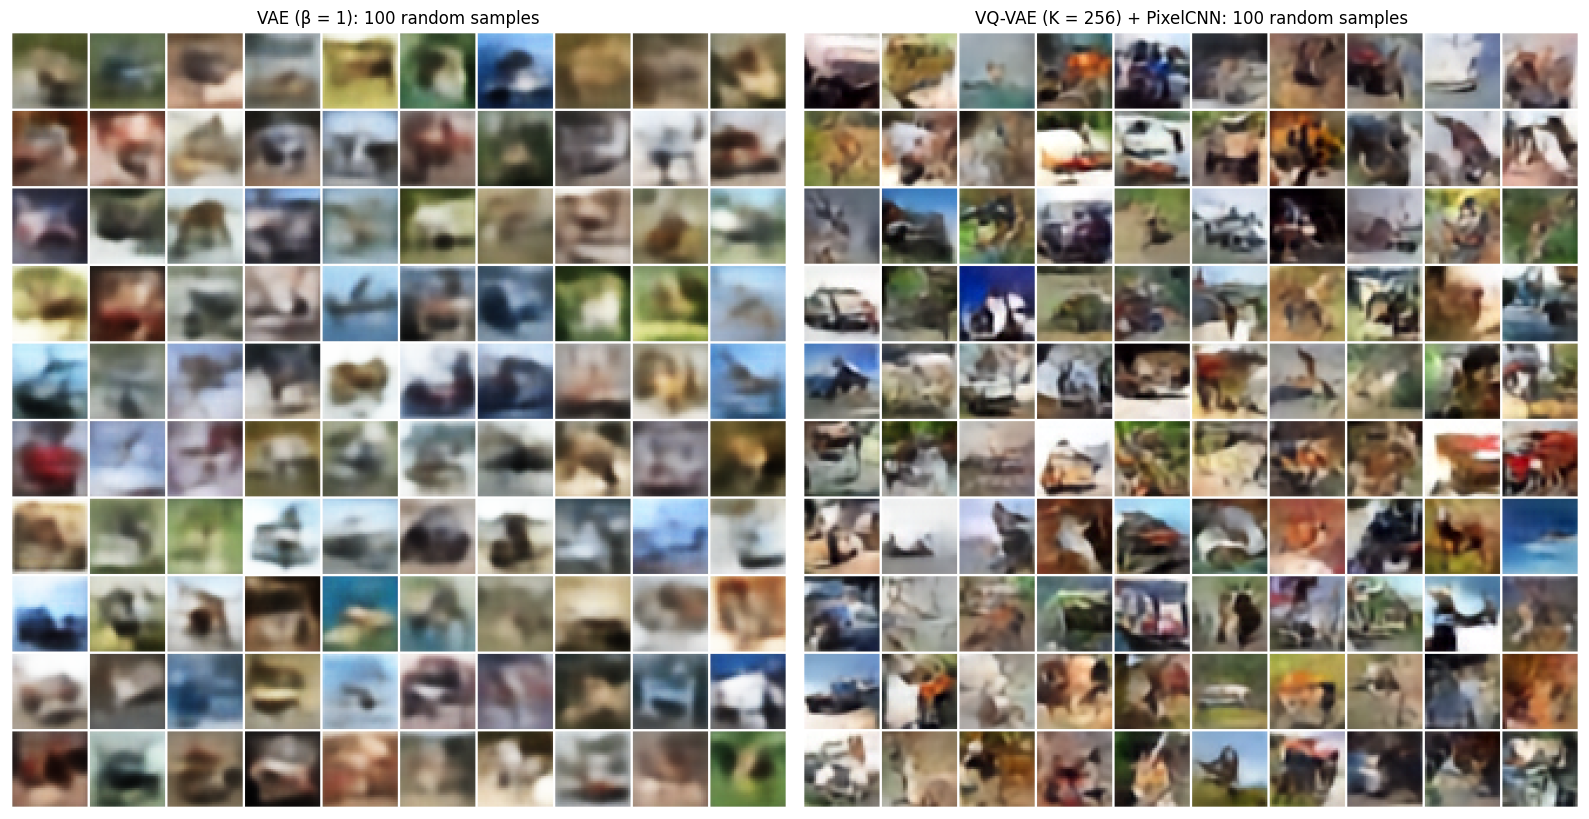

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8.2))
for a, imgs, t in zip(ax, [vae_samples[1], vq_samples[256 if 256 in vq_samples else CFG["ks"][0]]],
                      ["VAE (β = 1): 100 random samples", "VQ-VAE (K = 256) + PixelCNN: 100 random samples"]):
    a.imshow(to_grid(imgs, nrow=10, scale=3)); a.axis("off"); a.set_title(t)
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/partA_100_samples.png", dpi=150, bbox_inches="tight")
plt.show()

#### Verification Screenshots

Screenshots of performing the notebook on BITS Infra (Prayogshala) are submitted separately as `.jpg` files.